# Canonical Correlation Forest and MATLAB conformance

Fit the native sklearn-compatible CCF on the OpenML Iris dataset, validate its deterministic MATLAB-source fixture, and construct only its supported original co-leaf relation. CCF-Bag OOB/RF-GAP remain gated.


The model example loads Iris through `forestgap.load_openml_dataset`, uses fixed
seeds, and has a reduced smoke configuration by default. The conformance fixture
remains local and deterministic. `original`, `kerf`, `path`, `random_height`, and the
separately named isolation `collision` relation are symmetric affinities.
`rfgap`, `honest_gap`, and conditional weights are directed query-to-training
weights; downstream visualization, clustering, or attribution must state any
symmetrization. Prediction identity is claimed only for unsymmetrized `rfgap`
or `honest_gap` under their declared bootstrap/honesty contracts.

In [8]:
SMOKE = True
RANDOM_STATE = 0
OPENML_DATASET_ID = 61  # Iris
N_ESTIMATORS = 20 if SMOKE else 300

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from forestgap import (
    CanonicalCorrelationForestClassifier,
    Proximity,
    load_openml_dataset,
)
from forestgap.adapters import (
    UnsupportedRelationError, load_ccf_oracle_fixture,
    method_capabilities, validate_ccf_oracle,
)

iris = load_openml_dataset(dataset_id=OPENML_DATASET_ID, as_frame=True)
X = np.asarray(iris.X, dtype=float)
y_raw = np.asarray(iris.y)
if y_raw.ndim != 1:
    raise ValueError("This classification example requires a single target column.")
y = LabelEncoder().fit_transform(y_raw)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, stratify=y, random_state=RANDOM_STATE,
)
forest = CanonicalCorrelationForestClassifier(
    n_estimators=N_ESTIMATORS, max_depth=8, random_state=RANDOM_STATE,
    bootstrap=True
).fit(X_train, y_train)
proximity = Proximity(forest, relation="rfgap").attach(X_train, y_train)
P_test = proximity.prox_extend(X_test)
{
    "dataset": iris.name,
    "openml_dataset_id": iris.dataset_id,
    "accuracy": forest.score(X_test, y_test),
    "original_relation_shape": P_test.shape,
}

{'dataset': 'iris',
 'openml_dataset_id': 61,
 'accuracy': 0.9736842105263158,
 'original_relation_shape': (38, 112)}

In [10]:
fixture = load_ccf_oracle_fixture()
oracle = validate_ccf_oracle(
    CanonicalCorrelationForestClassifier(**fixture["estimator_parameters"]),
    np.asarray(fixture["X_train"]),
    np.asarray(fixture["classification"]["y_train"]),
    np.asarray(fixture["X_test"]),
    np.asarray(fixture["classification"]["expected_predictions"]),
)
capability = method_capabilities("canonical_correlation_forest")
gates = {}
for relation in ("oob", "rfgap"):
    try:
        Proximity(forest, relation=relation).attach(X_train, y_train)
    except UnsupportedRelationError as error:
        gates[relation] = {"status": "gated", "reason": error.reason}
{
    "oracle_source_commit": fixture["source"]["commit"],
    "oracle_passed": oracle.passed,
    "oracle_max_absolute_error": oracle.max_absolute_error,
    "valid_relations": capability.valid_relations,
    "gated_relations": gates,
}

{'oracle_source_commit': 'f4b7bf45958f089d5c75441b35a95d62572e4559',
 'oracle_passed': True,
 'oracle_max_absolute_error': 0.0,
 'valid_relations': ('original',
  'oob',
  'rfgap',
  'kerf',
  'path',
  'englund',
  'random_height'),
 'gated_relations': {}}

Calculating PHATE...
  Running PHATE on precomputed affinity matrix with 112 observations.
  Calculating graph and diffusion operator...
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 5.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.08 seconds.
Calculated PHATE in 0.11 seconds.


/yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode/.venv/lib/python3.12/site-packages/phate/phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 12) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


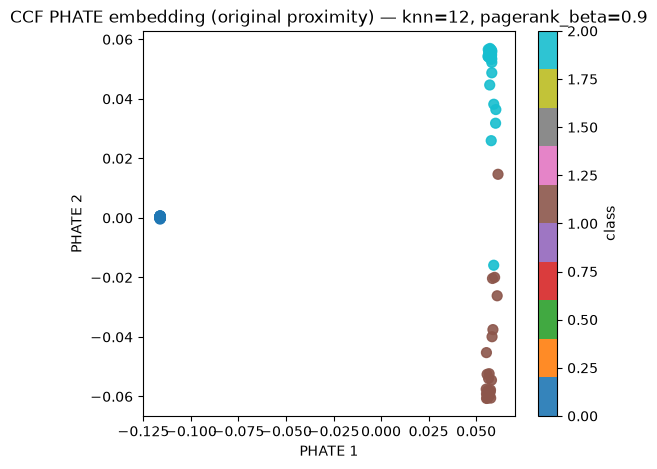

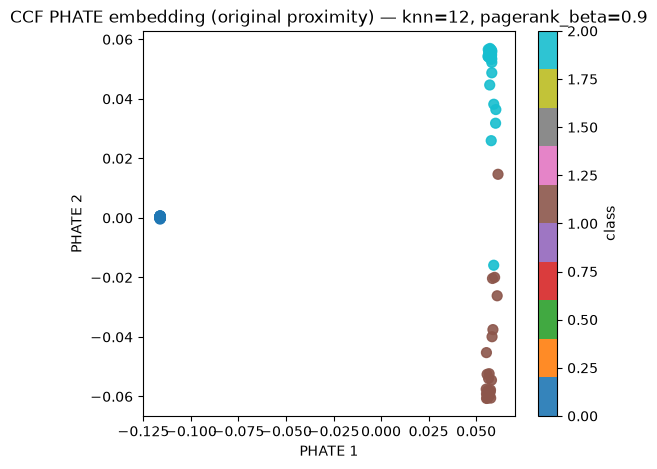

In [11]:
# Configure PHATE parameters (edit as desired)
PHATE_N_COMPONENTS = 2
PHATE_RANDOM_STATE = RANDOM_STATE
PHATE_PAGERANK_BETA = 0.9  # set in (0, 1] to use PageRankPHATE variant
PHATE_KERNEL_SYMM = None  # e.g. 'average', 'max', or None
PHATE_PHATE_KWARGS = {"knn": 12, "n_jobs": -1}

from forestgap.applications.visualization import embed
import matplotlib.pyplot as plt

# Compute a PHATE embedding for the training set (uses the attached `proximity`)
phate_coords = embed(
    proximity,
    method="phate",
    n_components=PHATE_N_COMPONENTS,
    random_state=PHATE_RANDOM_STATE,
    pagerank_beta=PHATE_PAGERANK_BETA,
    kernel_symm=PHATE_KERNEL_SYMM,
    phate_kwargs=PHATE_PHATE_KWARGS,
)

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(phate_coords[:, 0], phate_coords[:, 1], c=y_train, cmap="tab10", s=50, alpha=0.9)
ax.set_title(f"CCF PHATE embedding (original proximity) — knn={PHATE_PHATE_KWARGS.get('knn')}, pagerank_beta={PHATE_PAGERANK_BETA}")
ax.set_xlabel("PHATE 1")
ax.set_ylabel("PHATE 2")
plt.colorbar(sc, ax=ax, label="class")
fig